In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Global styling
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Load cleaned data
df = pd.read_csv('../data/zomato_cleaned.csv')

print(f"Loaded {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head(3)

Loaded 9,937 rows × 12 columns


,address,name,online_order,book_table,rate,votes,location,rest_type,cuisines,cost_for_two,listed_in(type),listed_in(city)
0,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1,775,Banashankari,Casual Dining,"North Indian, Mughlai, Chinese",800,Buffet,Banashankari
1,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1,787,Banashankari,Casual Dining,"Chinese, North Indian, Thai",800,Buffet,Banashankari
2,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8,918,Banashankari,"Cafe, Casual Dining","Cafe, Mexican, Italian",800,Buffet,Banashankari


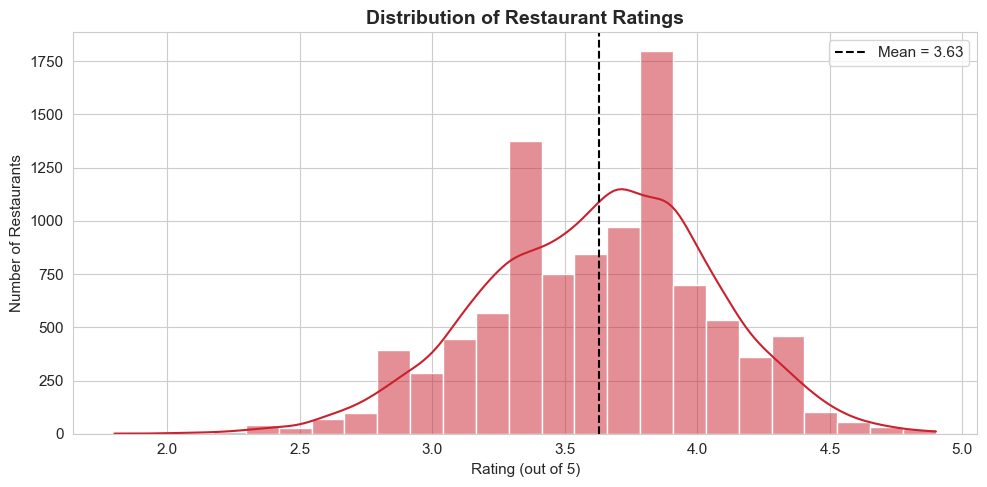

In [2]:
plt.figure(figsize=(10, 5))
sns.histplot(df['rate'], bins=25, kde=True, color='#cb202d')

plt.title('Distribution of Restaurant Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Rating (out of 5)')
plt.ylabel('Number of Restaurants')
plt.axvline(df['rate'].mean(), color='black', linestyle='--', 
            label=f"Mean = {df['rate'].mean():.2f}")
plt.legend()
plt.tight_layout()
plt.savefig('../dashboard/rating_distribution.png', dpi=100, bbox_inches='tight')
plt.show()

C:\Users\ZISHAN-PC\AppData\Local\Temp\ipykernel_15580\1881403369.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_locations.values, y=top_locations.index, palette='Reds_r')


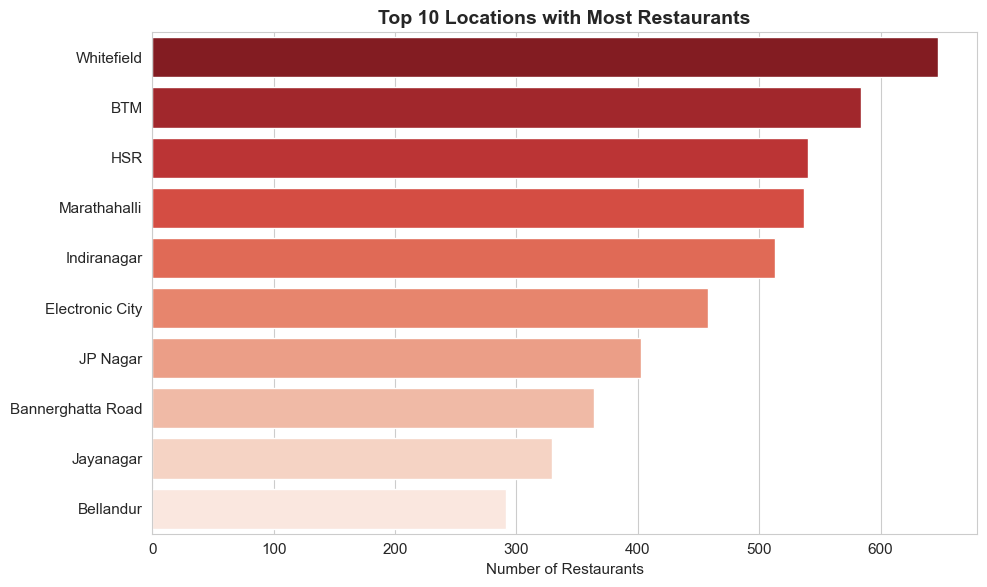

In [3]:
top_locations = df['location'].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_locations.values, y=top_locations.index, palette='Reds_r')

plt.title('Top 10 Locations with Most Restaurants', fontsize=14, fontweight='bold')
plt.xlabel('Number of Restaurants')
plt.ylabel('')
plt.tight_layout()
plt.savefig('../dashboard/top_locations.png', dpi=100, bbox_inches='tight')
plt.show()

C:\Users\ZISHAN-PC\AppData\Local\Temp\ipykernel_15580\3549706833.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_cuisines.values, y=top_cuisines.index, palette='viridis')


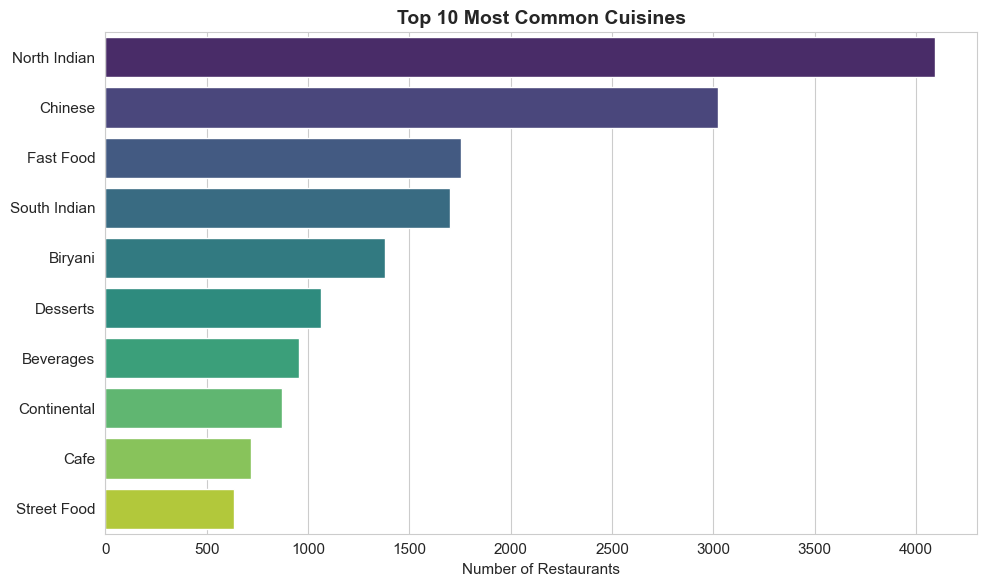

In [4]:
# A restaurant can serve multiple cuisines ("North Indian, Chinese") — split them
from collections import Counter

cuisine_list = df['cuisines'].str.split(',').explode().str.strip()
top_cuisines = cuisine_list.value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_cuisines.values, y=top_cuisines.index, palette='viridis')

plt.title('Top 10 Most Common Cuisines', fontsize=14, fontweight='bold')
plt.xlabel('Number of Restaurants')
plt.ylabel('')
plt.tight_layout()
plt.savefig('../dashboard/top_cuisines.png', dpi=100, bbox_inches='tight')
plt.show()

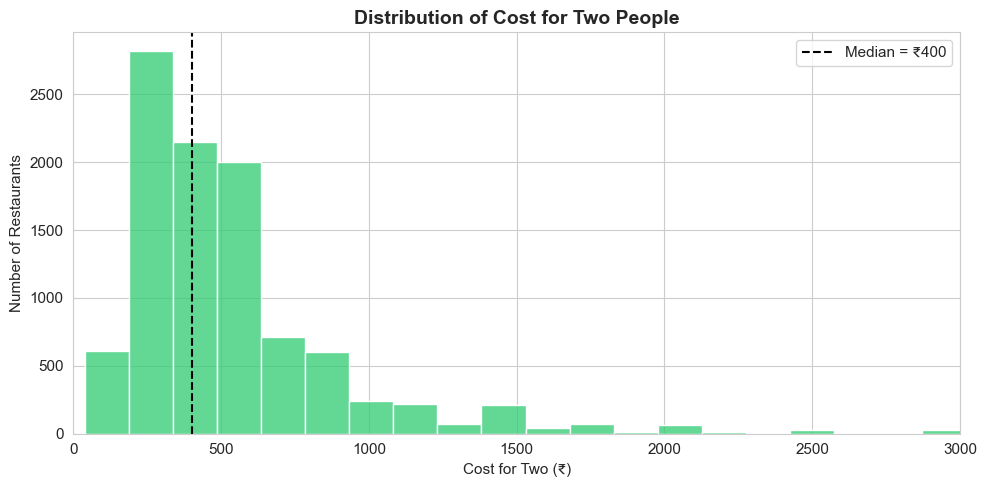

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(df['cost_for_two'], bins=40, color='#2ecc71')

plt.title('Distribution of Cost for Two People', fontsize=14, fontweight='bold')
plt.xlabel('Cost for Two (₹)')
plt.ylabel('Number of Restaurants')
plt.xlim(0, 3000)   # cut outliers for readability
plt.axvline(df['cost_for_two'].median(), color='black', linestyle='--',
            label=f"Median = ₹{df['cost_for_two'].median():,.0f}")
plt.legend()
plt.tight_layout()
plt.savefig('../dashboard/cost_distribution.png', dpi=100, bbox_inches='tight')
plt.show()

C:\Users\ZISHAN-PC\AppData\Local\Temp\ipykernel_15580\1517635431.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='online_order', y='rate', palette='Set2')


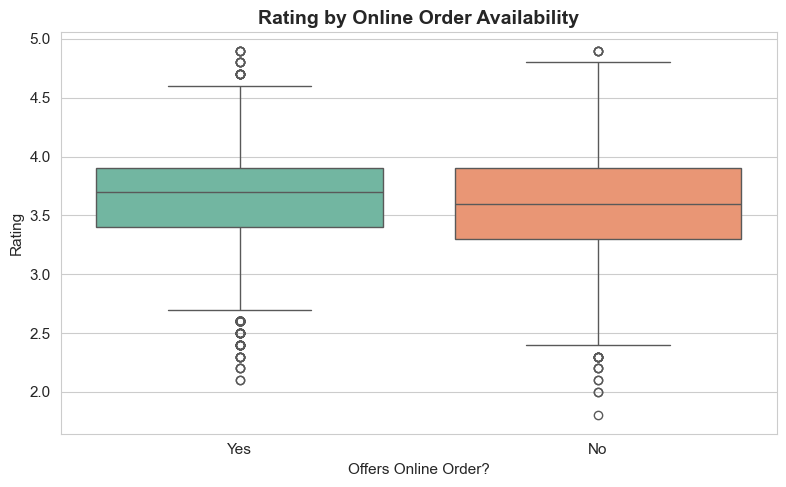

In [6]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='online_order', y='rate', palette='Set2')

plt.title('Rating by Online Order Availability', fontsize=14, fontweight='bold')
plt.xlabel('Offers Online Order?')
plt.ylabel('Rating')
plt.tight_layout()
plt.savefig('../dashboard/online_vs_rating.png', dpi=100, bbox_inches='tight')
plt.show()

C:\Users\ZISHAN-PC\AppData\Local\Temp\ipykernel_15580\1041074878.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_types.values, y=top_types.index, palette='magma')


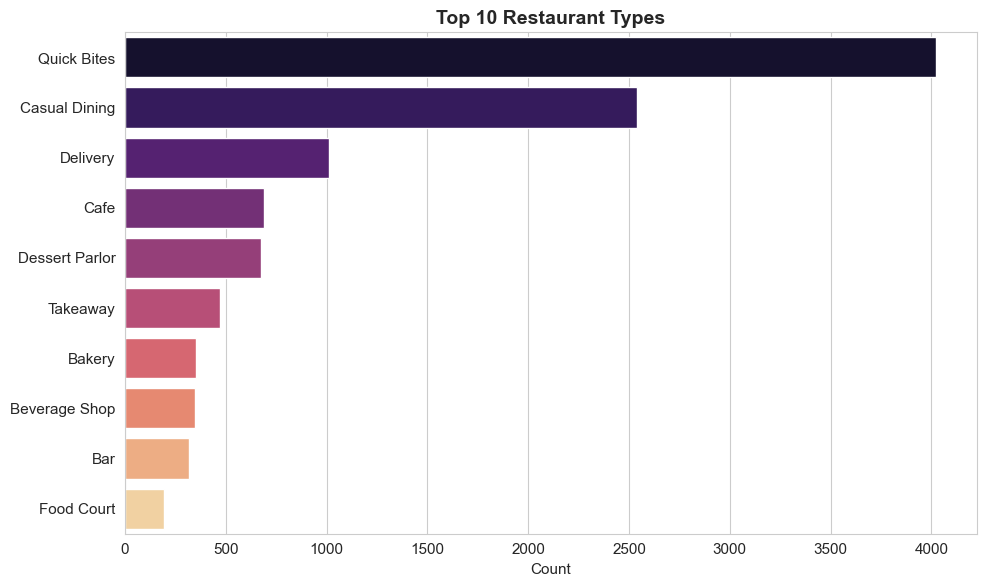

In [7]:
# Split multi-type entries too
type_list = df['rest_type'].str.split(',').explode().str.strip()
top_types = type_list.value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_types.values, y=top_types.index, palette='magma')

plt.title('Top 10 Restaurant Types', fontsize=14, fontweight='bold')
plt.xlabel('Count')
plt.ylabel('')
plt.tight_layout()
plt.savefig('../dashboard/restaurant_types.png', dpi=100, bbox_inches='tight')
plt.show()

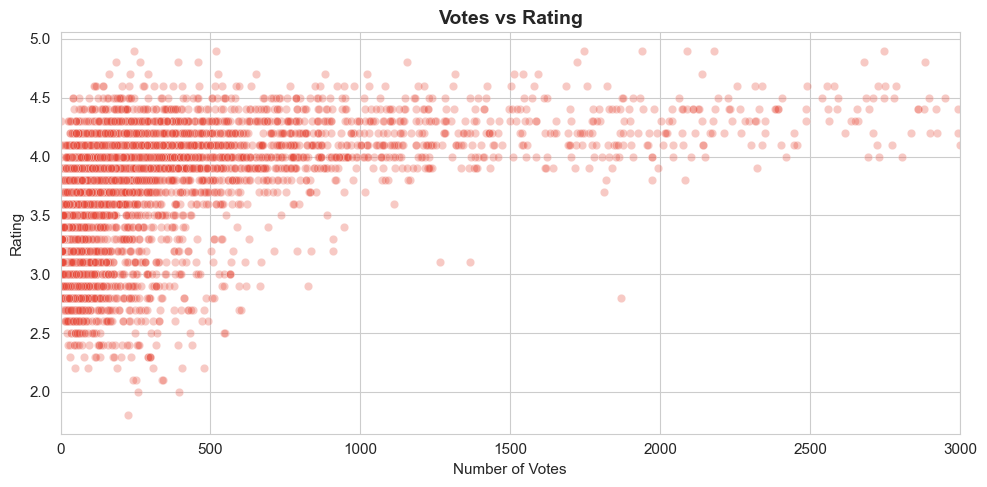

In [8]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='votes', y='rate', alpha=0.3, color='#e74c3c')

plt.title('Votes vs Rating', fontsize=14, fontweight='bold')
plt.xlabel('Number of Votes')
plt.ylabel('Rating')
plt.xlim(0, 3000)
plt.tight_layout()
plt.savefig('../dashboard/votes_vs_rating.png', dpi=100, bbox_inches='tight')
plt.show()

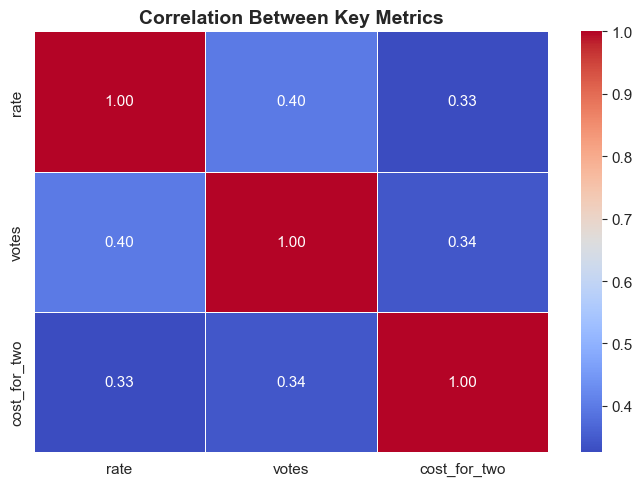

In [9]:
plt.figure(figsize=(7, 5))
numeric_df = df[['rate', 'votes', 'cost_for_two']]
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', 
            fmt='.2f', linewidths=0.5)

plt.title('Correlation Between Key Metrics', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../dashboard/correlation.png', dpi=100, bbox_inches='tight')
plt.show()

C:\Users\ZISHAN-PC\AppData\Local\Temp\ipykernel_15580\2608557237.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_rated, y='name', x='rate', palette='Greens_r')


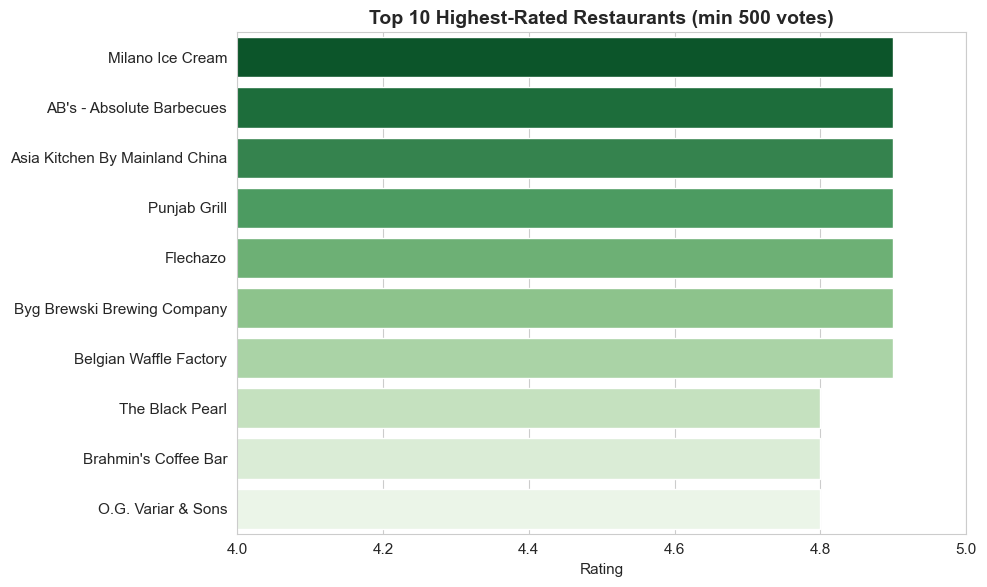

,name,rate,votes,cuisines,location
6494,Milano Ice Cream,4.9,2090,"Ice Cream, Desserts",Indiranagar
3810,AB's - Absolute Barbecues,4.9,6375,"European, Mediterranean, North Indian, BBQ",BTM
3820,Asia Kitchen By Mainland China,4.9,2178,"Asian, Chinese, Thai, Momos",Koramangala 5th Block
3378,Punjab Grill,4.9,518,North Indian,Whitefield
3069,Flechazo,4.9,2745,"Asian, Mediterranean, North Indian, BBQ",Whitefield
1772,Byg Brewski Brewing Company,4.9,16345,"Continental, North Indian, Italian, South Indi...",Sarjapur Road
2375,Belgian Waffle Factory,4.9,1746,Desserts,Brigade Road
1626,The Black Pearl,4.8,7023,"North Indian, European, Mediterranean, BBQ",Marathahalli
1546,Brahmin's Coffee Bar,4.8,2679,South Indian,Basavanagudi
8418,O.G. Variar & Sons,4.8,1156,"Bakery, Desserts",Rajajinagar


In [10]:
# Filter to avoid tiny-sample bias
top_rated = (
    df[df['votes'] >= 500]
    .sort_values('rate', ascending=False)
    .drop_duplicates('name')
    .head(10)[['name', 'rate', 'votes', 'cuisines', 'location']]
)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_rated, y='name', x='rate', palette='Greens_r')

plt.title('Top 10 Highest-Rated Restaurants (min 500 votes)', 
          fontsize=14, fontweight='bold')
plt.xlabel('Rating')
plt.ylabel('')
plt.xlim(4.0, 5.0)
plt.tight_layout()
plt.savefig('../dashboard/top_rated.png', dpi=100, bbox_inches='tight')
plt.show()

top_rated